# 数値計算演習B：軸対称 Poisson 方程式の数値解法

**テキスト付録B対応。第2章の発展内容です。**

第2章で学んだ中心差分を $(R,z)$ の2次元格子へ広げます。Miyamoto–Nagai モデルを検証用に使い、対称軸の処理、格子点の番号付け、境界値の移項、疎行列の構成を確かめます。その後、解析解との比較、残差、格子収束から結果を判断します。

Ryden §6.5 は物理的な題材の対応を示します。2次元 Poisson 方程式の数値解法は本教材で加えた発展です。数値計算法は、幸谷『Python数値計算プログラミング』第8章と§14.2.3を参考にします。

本演習では、離散化から検証までの手順を追うために、有限差分と疎行列の求解を使います。実際の重力計算をすべてこの方法で行うわけではなく、固定重力場の展開法や粒子分布からの重力計算法との関係は、基本学習とは別の補足で紹介します。

## 学習目標

- 軸対称 Poisson 方程式を、計算領域と境界条件を定めた2次元の境界値問題として設定できる。
- 中心差分を2次元へ拡張し、対称軸での滑らかさを使って軸上の差分式を導ける。
- 格子点と未知数番号を対応させ、既知の境界値を右辺に組み込んだ疎行列の連立一次方程式を構成できる。
- 解析解との比較と格子収束試験から、2次元有限差分解の誤差と収束次数を評価できる。
- 残差とポテンシャルの誤差を区別し、境界条件の近似誤差を除いて離散化誤差を検証する理由を説明できる。


## 実行順序とテキストとの対応

この Notebook は、他の Notebook の実行結果を読み込まずに、上から順に実行できます。設定を変更した場合は、カーネルを再起動して全セルを実行してください。

| テキストの内容 | Notebook B の節名 |
| --- | --- |
| B.1 Poisson 方程式と検証用モデル | 「Miyamoto–Nagai モデルの2次元 Poisson 方程式」 |
| B.2 差分式と対称軸 | 「2次元有限差分」 |
| B.3 格子の番号付けと連立一次方程式 | 「小格子の番号付けと疎行列の組み立て」 |
| B.4–B.5 疎行列の大きさ・数値解・残差 | 「2次元 Poisson 方程式の数値解」 |
| B.6 格子収束 | 「2次元 Poisson 方程式の格子収束」 |
| B.4の補足 | 「シミュレーション天文学で使う重力計算法」 |

導出はテキスト付録Bにあります。小格子で番号付けを確認してから、完全なソルバーを実行します。本文の Listing B.1–B.5 は、このソルバーの主要な操作に対応します。

付録Aの円盤の質量積分とは独立に学べます。また、第3章・付録Cの軌道計算へ進む前に本付録を終える必要はありません。Notebook C の軌道計算は解析的な加速度を使い、ここで求める数値ポテンシャルは入力しません。


In [1]:
import numpy as np
import matplotlib.pyplot as plt

G = 1.0

OI = {
    "orange": "#E69F00",
    "sky": "#56B4E9",
    "green": "#009E73",
    "yellow": "#F0E442",
    "blue": "#0072B2",
    "vermillion": "#D55E00",
    "purple": "#CC79A7",
    "black": "#000000",
}

plt.rcParams["figure.figsize"] = (6.5, 4.5)
plt.rcParams["font.size"] = 11


# 1. Miyamoto–Nagai モデルの2次元 Poisson 方程式

軸対称性 $\partial/\partial\phi=0$ を使うと、Poisson 方程式は
$$
\frac{\partial^2\Phi}{\partial R^2}+\frac{1}{R}\frac{\partial\Phi}{\partial R}+\frac{\partial^2\Phi}{\partial z^2}=4\pi G\rho(R,z)
$$
となります。密度 $\rho$ を入力とし、境界条件と合わせて未知の $\Phi$ を求めます。

検証用に、全質量 $M$ と長さのパラメータ $a>0,b>0$ を持つ Miyamoto–Nagai モデルを使います。$B=\sqrt{z^2+b^2}$ とおくと、
$$
\Phi(R,z)=-\frac{GM}{\sqrt{R^2+(a+B)^2}},\qquad
\rho(R,z)=\frac{b^2M}{4\pi}\frac{aR^2+(a+3B)(a+B)^2}{B^3[R^2+(a+B)^2]^{5/2}}
$$
です。`phi_mn` が解析ポテンシャル、`rho_mn` が対応する密度を返します。密度をもとに得た数値解を `phi_mn` と比較します。

既定値は $G=M=a=1,b=0.25$ です。計算・解析解・診断量には、同じ設定値 `G, Mmn, amn, bmn` を渡します。以下の密度図は描画用の格子であり、Poisson 方程式を解く格子とは別です。

**導出とモデルの式：テキスト付録B「軸対称 Poisson 方程式と検証用モデル」。**


In [2]:
from scipy import sparse
from scipy.sparse.linalg import spsolve

# モデルの質量と長さのパラメータ
Mmn = 1.0
amn = 1.0
bmn = 0.25

def phi_mn(R, z, G=1.0, M=1.0, a=1.0, b=0.25):
    # 本文の B=sqrt(z^2+b^2) に対応する。
    zz = np.sqrt(z**2 + b**2)
    return -G * M / np.sqrt(R**2 + (a + zz)**2)

def rho_mn(R, z, M=1.0, a=1.0, b=0.25):
    zz = np.sqrt(z**2 + b**2)
    num = b**2 * M * (a * R**2 + (a + 3.0 * zz) * (a + zz)**2)
    den = 4.0 * np.pi * zz**3 * (R**2 + (a + zz)**2)**2.5
    return num / den


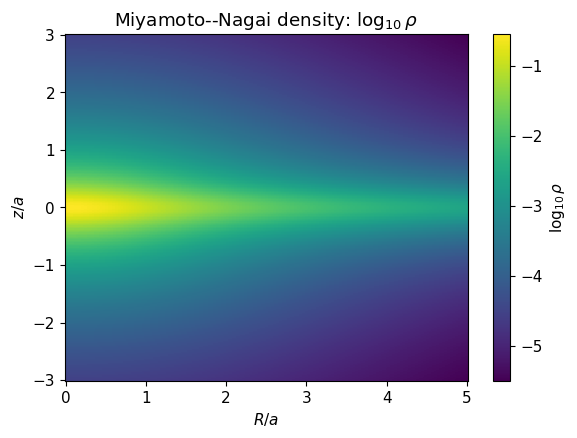

In [3]:
R2 = np.linspace(0.0, 5.0 * amn, 250)
z2 = np.linspace(-3.0 * amn, 3.0 * amn, 250)
# indexing="ij" とすると RR[i,j]=R2[i], ZZ[i,j]=z2[j] となり、
# 配列の第1軸を R、第2軸を z として扱える。
RR, ZZ = np.meshgrid(R2, z2, indexing="ij")
rho2 = rho_mn(RR, ZZ, Mmn, amn, bmn)

fig, ax = plt.subplots()
# rho2 の形は (R, z) だが、pcolormesh(x, y, C) は C の軸を (y, x) と見るため、
# 描画時だけ転置 .T して (z, R) に並べ替える。
im = ax.pcolormesh(R2 / amn, z2 / amn, np.log10(rho2.T), shading="auto")
ax.set_xlabel(r"$R/a$")
ax.set_ylabel(r"$z/a$")
ax.set_title(r"Miyamoto--Nagai density: $\log_{10}\rho$")
fig.colorbar(im, ax=ax, label=r"$\log_{10}\rho$")
plt.show()


# 2. 2次元有限差分

計算領域を $0\le R\le R_{\max}$、$-Z_{\max}\le z\le Z_{\max}$ とします。各方向を $N_R,N_Z$ **区間**に分けると、
$$
\Delta R=R_{\max}/N_R,\qquad \Delta z=2Z_{\max}/N_Z,
$$
$$
R_i=i\Delta R\quad(i=0,\ldots,N_R),\qquad z_j=-Z_{\max}+j\Delta z\quad(j=0,\ldots,N_Z)
$$
です。両端を含めるので、配列の形は `(NR + 1, NZ + 1)` になります。

## 内部点の5点ステンシル

$R_i>0$ の内部点では、第2章の中心差分を各方向に適用します。
$$
\Phi_{RR}\simeq\frac{\Phi_{i+1,j}-2\Phi_{i,j}+\Phi_{i-1,j}}{(\Delta R)^2},\qquad
\Phi_R\simeq\frac{\Phi_{i+1,j}-\Phi_{i-1,j}}{2\Delta R},
$$
$$
\Phi_{zz}\simeq\frac{\Phi_{i,j+1}-2\Phi_{i,j}+\Phi_{i,j-1}}{(\Delta z)^2}.
$$
差分方程式は
$$
c_-\Phi_{i-1,j}+c_0\Phi_{i,j}+c_+\Phi_{i+1,j}+c_z\Phi_{i,j-1}+c_z\Phi_{i,j+1}=4\pi G\rho_{i,j}
$$
で、係数は
$$
c_\pm=\frac{1}{(\Delta R)^2}\pm\frac{1}{2R_i\Delta R},\qquad
c_z=\frac{1}{(\Delta z)^2},\qquad c_0=-\frac{2}{(\Delta R)^2}-\frac{2}{(\Delta z)^2}
$$
となります。コードの `cm, cp, cz, center` が、それぞれ $c_-,c_+,c_z,c_0$ です。`center` は $z$ 方向の寄与から初期化し、$R$ 方向の寄与を加えます。

## 対称軸 $R=0$ の処理

軸上でも滑らかな軸対称ポテンシャルでは、軸を横切る符号付き座標で見た関数は偶関数です。その Taylor 展開は
$$
\Phi(R,z)=\Phi(0,z)+\frac12\Phi_{RR}(0,z)R^2+O(R^4)
$$
となり、$\Phi_R(0,z)=0$、$\Phi_R/R\to\Phi_{RR}(0,z)$ が分かります。したがって、
$$
\left[\Phi_{RR}+\frac{\Phi_R}{R}\right]_{R=0}=2\Phi_{RR}(0,z)
$$
です。仮想点を $\Phi_{-1,j}=\Phi_{1,j}$ とすれば、
$$
2\Phi_{RR}(0,z_j)\simeq\frac{4(\Phi_{1,j}-\Phi_{0,j})}{(\Delta R)^2}
$$
を得ます。軸上では `cp = 4.0 / dR**2` とし、中心係数に `-4.0 / dR**2` を加えます。負の $R$ の配列は不要です。軸対称性だけでなく、軸上の滑らかさを仮定しています。

## 境界値と未知点

$R=R_{\max}$ と $z=\pm Z_{\max}$ の3辺には解析ポテンシャルを与えます。対称軸 $R=0$ の値は未知数として残し、上の軸上の差分式で求めます。

解析的な境界値を使うのは、境界条件の近似誤差を除いて差分法を検証するためです。有限領域の外の密度を0としたモデルではなく、その外側の質量の寄与も解析的な境界値に含まれています。丸め誤差や線形方程式の求解に伴う誤差は別に残ります。

**導出：テキスト付録B「2次元有限差分」。Listing B.1・B.2 が内部点と対称軸の係数に対応します。**


## 小格子の番号付けと疎行列の組み立て

未知格子点は $i=0,\ldots,N_R-1$、$j=1,\ldots,N_Z-1$ です。$n_z=N_Z-1$ とし、
$$
p=i\,n_z+(j-1)
$$
で1次元番号を付けます。`idx(i, j)` がこの番号を返し、解ベクトルの `sol[p]` が格子上の `Phi[i, j]` に対応します。

まず、本文の格子・疎行列の図と同じ $N_R=4,N_Z=5$ を使います。未知点は $i=0,1,2,3$、$j=1,2,3,4$ の16点です。$i=4$ と $j=0,5$ は既知の境界です。$(i,j)=(1,2)$ の番号は5で、近傍点を含む番号は $1,4,5,6,9$ となります。番号3と4は連番ですが、格子上の鉛直方向の近傍ではありません。

**自分で書く部分：** `p=0,...,15` から元の `(i,j)` を返す処理を書いてください。商と余りを使い、`p = i * 4 + (j - 1)` に戻して同じ値になることを確認します。

### 非零係数と既知の境界値

一つの差分方程式が結ぶのは近傍点だけなので、係数行列は疎行列です。`rows[k], cols[k], data[k]` に、非零要素の行番号・列番号・値を記録します。

行番号 `p` の右辺は、まず `4*pi*G*rho` です。近傍点が未知点なら、その係数を行列の対応する列へ入れます。既知の境界点なら列を作らず、係数と解析境界値の積を右辺から差し引きます。例えば外側の境界では
$$
b_p\leftarrow b_p-c_+\Phi_{N_R,j}^{\mathrm{exact}}
$$
です。右辺ベクトル $\boldsymbol b$ と、モデルの長さ $b$ は別の量です。

全行の係数を集めた後、`sparse.csr_matrix` で CSR 形式（非零要素を行ごとにまとめる形式）へ変換し、`spsolve(A, rhs)` で解きます。最後に解析境界値を2次元配列へ入れ、未知点へ `sol[idx(i,j)]` を戻します。

**対応：テキスト付録B「2次元格子での連立一次方程式の組み立て」、Listing B.3–B.5。**


In [4]:
# 本文の説明用格子 NR=4, NZ=5 と同じ16未知点を並べる
nR_demo = 4
nZ_demo = 4
index_demo = np.empty((nR_demo, nZ_demo), dtype=int)
for i_demo in range(nR_demo):
    for j_demo in range(1, nZ_demo + 1):
        p_demo = i_demo * nZ_demo + (j_demo - 1)
        index_demo[i_demo, j_demo - 1] = p_demo
        print(f"(i,j)=({i_demo},{j_demo}) → p={p_demo}")
print("行が i、列が j=1,2,3,4 の番号表:\n", index_demo)


(i,j)=(0,1) → p=0
(i,j)=(0,2) → p=1
(i,j)=(0,3) → p=2
(i,j)=(0,4) → p=3
(i,j)=(1,1) → p=4
(i,j)=(1,2) → p=5
(i,j)=(1,3) → p=6
(i,j)=(1,4) → p=7
(i,j)=(2,1) → p=8
(i,j)=(2,2) → p=9
(i,j)=(2,3) → p=10
(i,j)=(2,4) → p=11
(i,j)=(3,1) → p=12
(i,j)=(3,2) → p=13
(i,j)=(3,3) → p=14
(i,j)=(3,4) → p=15
行が i、列が j=1,2,3,4 の番号表:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]
 [12 13 14 15]]


In [5]:
def solve_mn_poisson(NR=40, NZ=64, Rmax=5.0, Zmax=4.0, G=1.0, M=1.0, a=1.0, b=0.25):
    """軸対称 Poisson 方程式を解き、格子・2次元解・疎行列・右辺・解ベクトルを返す。"""
    for n in (NR, NZ):
        if isinstance(n, bool) or not isinstance(n, (int, np.integer)) or n < 2:
            raise ValueError("NR と NZ は2以上の整数にしてください。")
    if not all(np.isfinite(x) and x > 0 for x in (Rmax, Zmax, G, M, b)):
        raise ValueError("Rmax, Zmax, G, M, b は有限の正数にしてください。")
    if not np.isfinite(a) or a < 0:
        raise ValueError("a は有限の非負数にしてください。")

    # NR, NZ は区間数。両端を含む格子点数はそれぞれ NR+1, NZ+1。
    R = np.linspace(0.0, Rmax, NR + 1)
    z = np.linspace(-Zmax, Zmax, NZ + 1)
    dR = R[1] - R[0]
    dz = z[1] - z[0]

    # 未知点は i=0,...,NR-1, j=1,...,NZ-1。対称軸 i=0 は未知数に含む。
    nR_u = NR
    nZ_u = NZ - 1
    n_unknown = nR_u * nZ_u

    def idx(i, j):
        # 各 i について j の順に並べる。j=0 は境界なので1を引く。
        return i * nZ_u + (j - 1)

    # 非零要素の行番号・列番号・値だけを記録する。
    rows, cols, data = [], [], []
    rhs = np.zeros(n_unknown)

    for i in range(nR_u):
        Ri = R[i]
        for j in range(1, NZ):
            p = idx(i, j)
            rhs[p] = 4.0 * np.pi * G * rho_mn(Ri, z[j], M, a, b)

            # z 方向の中心差分。既知の上下端の寄与は右辺から差し引く。
            cz = 1.0 / dz**2
            center = -2.0 / dz**2
            if j - 1 == 0:
                rhs[p] -= cz * phi_mn(Ri, z[0], G, M, a, b)
            else:
                rows.append(p)
                cols.append(idx(i, j - 1))
                data.append(cz)
            if j + 1 == NZ:
                rhs[p] -= cz * phi_mn(Ri, z[NZ], G, M, a, b)
            else:
                rows.append(p)
                cols.append(idx(i, j + 1))
                data.append(cz)

            # R 方向の寄与を加える。軸上では 2 Phi_RR の差分を使う。
            if i == 0:
                cp = 4.0 / dR**2
                center += -4.0 / dR**2
                rows.append(p)
                cols.append(idx(1, j))
                data.append(cp)
            else:
                cp = 1.0 / dR**2 + 1.0 / (2.0 * Ri * dR)
                cm = 1.0 / dR**2 - 1.0 / (2.0 * Ri * dR)
                center += -2.0 / dR**2
                rows.append(p)
                cols.append(idx(i - 1, j))
                data.append(cm)

                # 外側の近傍が境界なら右辺へ、未知点なら行列へ入れる。
                if i + 1 == NR:
                    rhs[p] -= cp * phi_mn(R[NR], z[j], G, M, a, b)
                else:
                    rows.append(p)
                    cols.append(idx(i + 1, j))
                    data.append(cp)

            # 行 p の中心点の係数は、同じ列番号 p に入れる。
            rows.append(p)
            cols.append(p)
            data.append(center)

    shape = (n_unknown, n_unknown)
    A = sparse.csr_matrix((data, (rows, cols)), shape=shape)
    sol = spsolve(A, rhs)

    # 既知の3辺を設定してから、解ベクトルを2次元の未知点へ戻す。
    Phi = np.empty((NR + 1, NZ + 1))
    Phi[:, 0] = phi_mn(R, z[0], G, M, a, b)
    Phi[:, NZ] = phi_mn(R, z[NZ], G, M, a, b)
    Phi[NR, :] = phi_mn(R[NR], z, G, M, a, b)
    for i in range(nR_u):
        for j in range(1, NZ):
            Phi[i, j] = sol[idx(i, j)]

    return R, z, Phi, A, rhs, sol


## 補足：シミュレーション天文学で使う重力計算法

この補足は、テキスト付録Bの同名の補足に対応します。以下の方法を実装する課題ではなく、本演習で学ぶ有限差分法と研究で用いる重力計算法の関係を説明します。

本演習では、Poisson 方程式を有限差分で離散化し、疎行列の連立一次方程式を解きます。これは境界値問題の設定から数値解の検証までを学ぶための一例であり、すべての重力計算で同じ手順を使うわけではありません。

### 滑らかな固定重力場

複雑な質量分布の重力場には、角度依存性を球面調和関数で表す**多重極展開（multipole expansion）**や、密度とポテンシャルを対応する基底関数の和で表す**基底関数展開法（basis-function expansion）**などを使えます。あらかじめ構成した展開式や補間関数を微分すれば、任意の位置で加速度を評価できます。固定場での軌道積分中に、空間上の Poisson 方程式を解き直す必要はありません。多重極展開は、第2章で紹介した遠方の境界値だけでなく、質量分布の内部の重力場を表すことにも用いられます。

### 格子上の自己重力計算

一様格子では、**高速 Fourier 変換（fast Fourier transform; FFT）**を利用して Poisson 方程式を解く方法があり、周期境界条件と組み合わせやすくなっています。粗い格子と細かい格子を組み合わせて離散方程式を解く**多重格子法（multigrid method）**は、適合格子細分化法（adaptive mesh refinement; AMR）を用いる計算でも利用されます。

有限差分法は方程式の**離散化**、多重格子法は離散方程式の**求解**の方法であり、両者は組み合わせて使えます。FFT も有限差分法と対立するものではなく、有限差分で得た離散方程式を解くために利用する場合があります。

### 粒子分布からの重力計算

**ツリー法（tree method）**では、遠方の粒子群からの重力を、多重極展開を使ってまとめて近似します。**PM 法（particle-mesh method）**では、粒子の質量を格子へ割り当て、格子上でポテンシャルと加速度を求め、加速度を粒子位置へ補間します。格子上のポテンシャルを差分して加速度を求める実装もあり、PM 法も有限差分法と排他的な方法ではありません。

重力を長距離成分と短距離成分に分け、前者を PM 法、後者をツリー法で計算する TreePM 法もあります。

以上は用途に沿った例であり、排他的な分類ではありません。基底関数展開を自己重力系の時間発展に用いることもできます。研究では質量分布、境界条件、必要な空間分解能、計算規模に応じて方法を選びます。方法が変わっても、参照解との比較や、格子幅・展開の項数などの近似の細かさを変えた検証は必要です。

参考：Binney & Tremaine, *Galactic Dynamics*, 2nd ed. (2008), §2.4・§2.8・§2.9。松本ほか『輻射電磁流体シミュレーションの基礎』、富阪・花輪・牧野編『シミュレーション天文学』も参照できます。


# 3. 2次元 Poisson 方程式の数値解

$R_{\max}=5a,Z_{\max}=4a$ を固定し、$N_R=40,N_Z=64$ で解きます。格子幅はともに $0.125a$ です。未知数は $N_R(N_Z-1)=2520$ 個で、密行列ならその2乗の要素を保存します。非零要素数は疎行列の `nnz` から確認します。

ポテンシャルの誤差は、**全格子点での最大絶対誤差を一定の基準量 $GM/a$ で割った値**
$$
\epsilon_\Phi=\frac{\max_{i,j}|\Phi_{\mathrm{num},i,j}-\Phi_{\mathrm{exact},i,j}|}{GM/a}
$$
で測ります。各点のポテンシャルで割る相対誤差ではありません。

残差は未知点の解ベクトルから $\boldsymbol r_{\mathrm{res}}=A\boldsymbol\Phi-\boldsymbol b$ と計算します。数値解が離散方程式を満たす程度を測る量で、ポテンシャル誤差とは単位も異なります。方程式の規格化を変えると残差の値も変わるため、その大きさだけを異なる規格化の結果と比較しないようにします。

**対応：テキスト付録B「疎行列の大きさと構造」「数値解と誤差」。**


In [6]:
# 計算領域と各方向の区間数を指定する
NR, NZ = 40, 64
Rmax = 5.0 * amn
Zmax = 4.0 * amn
Rmn, zmn, Phi_num, A_mn, rhs_mn, sol_mn = solve_mn_poisson(
    NR=NR, NZ=NZ, Rmax=Rmax, Zmax=Zmax, G=G, M=Mmn, a=amn, b=bmn)

# 数値解と同じ格子上で解析ポテンシャルを評価する
RRmn, ZZmn = np.meshgrid(Rmn, zmn, indexing="ij")
Phi_exact_mn = phi_mn(RRmn, ZZmn, G, Mmn, amn, bmn)

# 解の誤差と、離散方程式の残差を別々に測る
err_phi = np.max(np.abs(Phi_num - Phi_exact_mn)) / (G * Mmn / amn)
residual = A_mn @ sol_mn - rhs_mn
residual_max = np.max(np.abs(residual))

print(f"未知数                       = {A_mn.shape[0]}")
print(f"非零行列要素数               = {A_mn.nnz}")
print(f"行列の非零要素率             = {A_mn.nnz / A_mn.shape[0]**2:.3e}")
print(f"規格化した Phi の最大誤差    = {err_phi:.6e}")
print(f"連立一次方程式の最大残差     = {residual_max:.6e}")


未知数                       = 2520
非零行列要素数               = 12394
行列の非零要素率             = 1.952e-03
規格化した Phi の最大誤差    = 4.260482e-03
連立一次方程式の最大残差     = 9.083446e-14


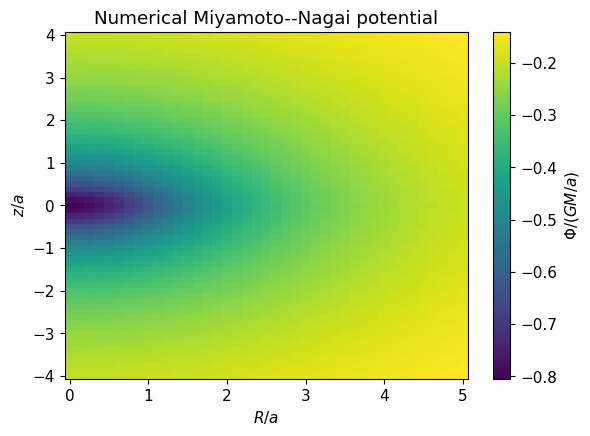

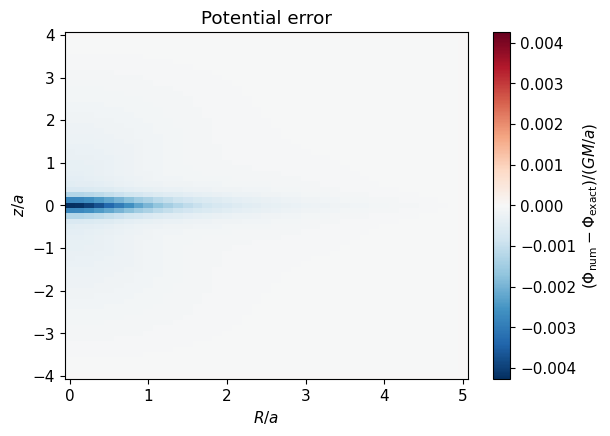

In [7]:
# 配列は (R,z) の順なので、描画時だけ (z,R) に転置する。
fig, ax = plt.subplots()
im = ax.pcolormesh(Rmn / amn, zmn / amn, Phi_num.T / (G * Mmn / amn), shading="auto")
ax.set_xlabel(r"$R/a$")
ax.set_ylabel(r"$z/a$")
ax.set_title("Numerical Miyamoto--Nagai potential")
fig.colorbar(im, ax=ax, label=r"$\Phi/(GM/a)$")
plt.show()

err_map = ((Phi_num - Phi_exact_mn) / (G * Mmn / amn)).T
err_lim = np.max(np.abs(err_map))

fig, ax = plt.subplots()
im = ax.pcolormesh(
    Rmn / amn, zmn / amn, err_map,
    shading="auto", cmap="RdBu_r", vmin=-err_lim, vmax=err_lim
)
ax.set_xlabel(r"$R/a$")
ax.set_ylabel(r"$z/a$")
ax.set_title("Potential error")
fig.colorbar(im, ax=ax, label=r"$(\Phi_{\rm num}-\Phi_{\rm exact})/(GM/a)$")
plt.show()


## 演習：2次元 Poisson 方程式の数値解法

1. 数値解と解析解を同じ格子上で比較し、既知の3辺では差が0、対称軸では一般に差が残ることを確認してください。
2. `solve_mn_poisson(NR=4, NZ=5)` で小さい行列を作り、`A.getrow(5).indices` に列番号 $1,4,5,6,9$ が現れることを確認してください。係数と各近傍点を対応させ、番号3と4を鉛直方向の近傍として結んではいけない理由を説明してください。
3. `nnz` と同じ大きさの密行列の全要素数を比較してください。元の行列の非零要素数だけから、直接法の計算時間まで決められるでしょうか。フィルインについてはテキスト付録Dを参照できます。
4. 残差が小さいのにポテンシャル誤差が残る理由と、境界に解析値を与えている理由を説明してください。
5. 軸上の動径方向の係数が $4/(\Delta R)^2$ になる過程を確かめてください。どこで軸対称性と滑らかさを使っていますか。

格子を細かくする実験は、次の節で計算領域とモデルを固定して行います。


# 4. 2次元 Poisson 方程式の格子収束

計算領域、モデルのパラメータ、解析的な境界条件を固定し、$N_R,N_Z$ を同じ比率で増やします。前の節で設定した `Rmax, Zmax` を引き続き使います。

$$
(N_R,N_Z)=(40,64),(60,96),(80,128),(100,160)
$$
では、常に $\Delta R=\Delta z$ です。各格子で、前節と同じ規格化した最大絶対誤差 $\epsilon_\Phi$ と
$$
h=\max(\Delta R,\Delta z)
$$
を求めます。片方の方向だけを細かくする試験とは異なります。

内部点と対称軸で使う差分は、滑らかな解に対して各方向で2次精度です。十分細かく、離散化誤差が支配する範囲では $\epsilon_\Phi\propto h^2$ が期待されます。ただし、局所的な打ち切り誤差の次数だけで数値解全体の収束が保証されるわけではないため、ソルバー全体で検証します。

$\epsilon_\Phi\propto h^p$ なら両対数表示の傾きが収束次数 $p$ になります。ここでは4格子すべてを直線の当てはめに使います。モデルや格子幅を変更した場合も、誤差がべき乗則に従う範囲かを確認してください。

**対応：テキスト付録B「2次元 Poisson 方程式の格子収束」。**


In [8]:
# 領域とモデルを固定し、両方向の区間数を同じ比率で増やす
grid_list = [(40, 64), (60, 96), (80, 128), (100, 160)]
h_list = []
err_list = []

for NR_i, NZ_i in grid_list:
    R_i, z_i, Phi_i, _, _, _ = solve_mn_poisson(
        NR=NR_i, NZ=NZ_i, Rmax=Rmax, Zmax=Zmax,
        G=G, M=Mmn, a=amn, b=bmn)

    # 同じ格子上の解析解から、規格化した最大絶対誤差を測る
    RR_i, ZZ_i = np.meshgrid(R_i, z_i, indexing="ij")
    Phi_ex_i = phi_mn(RR_i, ZZ_i, G, Mmn, amn, bmn)
    h_i = max(R_i[1] - R_i[0], z_i[1] - z_i[0])
    err_i = np.max(np.abs(Phi_i - Phi_ex_i)) / (G * Mmn / amn)
    h_list.append(h_i)
    err_list.append(err_i)
    print(f"(NR, NZ) = ({NR_i:2d}, {NZ_i:2d}), h = {h_i:.5f}, 誤差 = {err_i:.6e}")

h_list = np.array(h_list)
err_list = np.array(err_list)

# epsilon_Phi が h^p に比例する範囲では、両対数の傾きが p
order_2d = np.polyfit(np.log(h_list), np.log(err_list), 1)[0]
print(f"\n測定した収束次数 = {order_2d:.3f}")


(NR, NZ) = (40, 64), h = 0.12500, 誤差 = 4.260482e-03
(NR, NZ) = (60, 96), h = 0.08333, 誤差 = 1.832334e-03
(NR, NZ) = (80, 128), h = 0.06250, 誤差 = 1.022729e-03


(NR, NZ) = (100, 160), h = 0.05000, 誤差 = 6.523751e-04

測定した収束次数 = 2.048


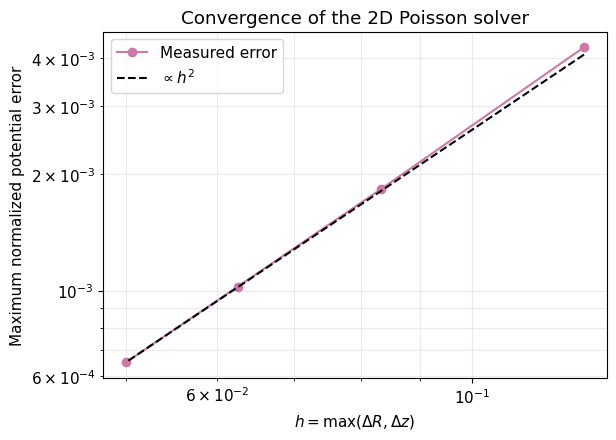

In [9]:
reference = err_list[-1] * (h_list / h_list[-1])**2

fig, ax = plt.subplots()
ax.loglog(h_list, err_list, "o-", color=OI["purple"], label="Measured error")
ax.loglog(h_list, reference, "--", color=OI["black"], label=r"$\propto h^2$")
ax.set_xlabel(r"$h=\max(\Delta R,\Delta z)$")
ax.set_ylabel("Maximum normalized potential error")
ax.set_title("Convergence of the 2D Poisson solver")
ax.legend()
ax.grid(alpha=0.25, which="both")
plt.show()


# まとめ

第2章の中心差分を2次元へ広げ、対称軸の滑らかさを使って軸上の係数を求めました。格子点と未知数番号を対応させ、未知の近傍点の係数は行列へ、既知の境界値の寄与は右辺へ入れました。

解析的な境界値によって境界条件の近似誤差を除き、ポテンシャルの誤差と離散方程式の残差を別々に測りました。残差が小さくても、連続な方程式に対する誤差は残ります。既定の4格子ではほぼ2次収束となりますが、モデルや境界条件を変えた場合も同じ検証が必要です。

補足では固定重力場の展開法、FFT・多重格子法、ツリー法・PM 法・TreePM 法も紹介していますが、この Notebook で実装・検証するのは有限差分と疎行列のソルバーです。Notebook C の軌道計算には、ここで得た数値ポテンシャルを入力しません。
